# Tipos de gráficos con matplotlib
**Diseño de Soluciones de IA · Sesión 3 · Tema 4**

Practicaremos los 7 gráficos de la tabla *"¿Qué gráfico uso?"* con el caso de los clientes de la tienda online (datos simulados).

```text
Quiero ver…                          Tipo de variable        Gráfico
─────────────────────────────────────────────────────────────────────────
1. Cómo se distribuye una variable   Numérica                Histograma
2. Valores atípicos y mediana        Numérica                Diagrama de caja
3. Cuántos hay de cada categoría     Categórica              Barras
4. Relación entre dos números        Numérica vs numérica    Dispersión
5. Si una variable cambia según      Numérica vs target      Cajas por grupo
   el target
6. Tasa del target por categoría     Categórica vs target    Barras de %
7. Relaciones entre muchas numéricas Varias numéricas        Mapa de correlación
```

**Regla:** todo gráfico lleva título, nombres de ejes y una conclusión escrita debajo.

## 0. Preparación: librerías y datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Generamos el dataset simulado (el mismo de la clase)
rng = np.random.default_rng(42)
n = 1000
distritos = ["Lima", "Surco", "Miraflores", "San Juan de Lurigancho", "Comas", "Los Olivos"]
edad = np.clip(rng.normal(36, 11, n), 18, 75).round()
distrito = rng.choice(distritos, n, p=[.22, .18, .12, .2, .14, .14])
canal = rng.choice(["App", "Web", "Tienda"], n, p=[.45, .35, .2])
compras_6m = rng.poisson(6, n)
monto_total = (compras_6m * rng.gamma(9, 9, n)).round(2)
dias_ultima_compra = np.clip(rng.exponential(40, n), 0, 365).round()
reclamos = rng.poisson(0.6, n)
usa_cupon = rng.choice(["Sí", "No"], n, p=[.4, .6])
fecha_registro = pd.to_datetime("2022-01-01") + pd.to_timedelta(rng.integers(0, 1400, n), unit="D")

# Variable objetivo: depende de recencia, reclamos, compras y cupón (el canal NO influye)
z = -1.6 + 0.035 * dias_ultima_compra + 0.7 * reclamos - 0.15 * compras_6m - 0.8 * (usa_cupon == "Sí")
se_fue = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)

clientes = pd.DataFrame({
    "id_cliente": [f"C{i:04d}" for i in range(1, n + 1)],
    "edad": edad, "distrito": distrito, "canal": canal,
    "compras_6m": compras_6m, "monto_total": monto_total,
    "dias_ultima_compra": dias_ultima_compra, "reclamos": reclamos,
    "usa_cupon": usa_cupon, "fecha_registro": fecha_registro.strftime("%Y-%m-%d"),
    "se_fue": se_fue,
})

# Problemas de calidad introducidos a propósito (como en datos reales)
idx = rng.choice(n, 50, replace=False); clientes.loc[idx, "edad"] = np.nan
idx = rng.choice(n, 30, replace=False); clientes.loc[idx, "monto_total"] = np.nan
idx = rng.choice(n, 60, replace=False)
clientes.loc[idx, "distrito"] = clientes.loc[idx, "distrito"].str.upper()
idx = rng.choice(n, 40, replace=False)
clientes.loc[idx, "distrito"] = clientes.loc[idx, "distrito"].str.lower() + " "
idx = rng.choice(n, 6, replace=False); clientes.loc[idx, "monto_total"] = clientes.loc[idx, "monto_total"] * 12
clientes = pd.concat([clientes, clientes.sample(15, random_state=1)], ignore_index=True)

# Limpieza rápida (lo vimos en el tema 5)
datos = clientes.drop_duplicates().copy()
datos["distrito"] = datos["distrito"].str.strip().str.title().replace("San Juan De Lurigancho", "San Juan de Lurigancho")
datos["edad"] = datos["edad"].fillna(datos["edad"].median())
datos["monto_total"] = datos["monto_total"].fillna(datos["monto_total"].median())
datos.loc[datos["monto_total"] > 5000, "monto_total"] = np.nan
datos["monto_total"] = datos["monto_total"].fillna(datos["monto_total"].median())

print(datos.shape)
datos.head()

(1000, 11)


,id_cliente,edad,distrito,canal,compras_6m,monto_total,dias_ultima_compra,reclamos,usa_cupon,fecha_registro,se_fue
0,C0001,39.0,San Juan de Lurigancho,Web,2,315.41,22.0,0,No,2022-12-27,1
1,C0002,25.0,Surco,Tienda,11,883.61,4.0,2,No,2025-01-03,0
2,C0003,44.0,Miraflores,App,7,553.75,11.0,0,No,2023-03-31,0
3,C0004,36.0,Miraflores,Web,6,268.90,34.0,0,No,2024-04-26,0
4,C0005,18.0,Lima,Web,5,327.99,155.0,1,Sí,2024-02-18,1


## 1. Histograma: ¿cómo se distribuye una variable numérica?

Divide los valores en intervalos (`bins`) y cuenta cuántos caen en cada uno.

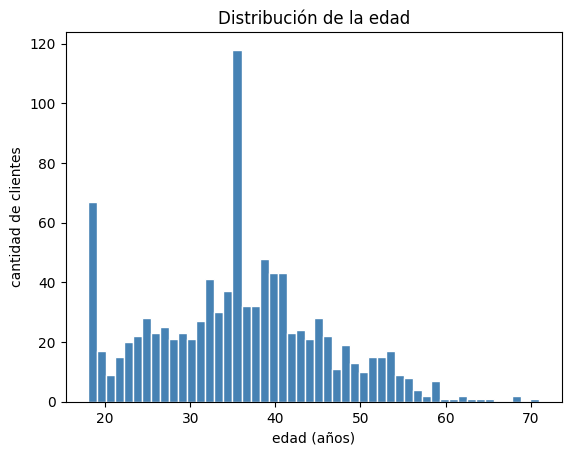

In [14]:
plt.hist(datos["edad"], bins=50, color="steelblue", edgecolor="white")
plt.title("Distribución de la edad")
plt.xlabel("edad (años)")
plt.ylabel("cantidad de clientes")
plt.show()

**Lectura:** la mayoría de clientes tiene entre 26 y 40 años. El pico en 36 aparece porque los nulos se rellenaron con la mediana (36).

👉 **Prueba:** cambia `bins=20` por `bins=5` y por `bins=50`. ¿Qué cambia?

## 2. Diagrama de caja: valores atípicos y mediana

```text
   ○  ○       ←  atípicos (fuera de los bigotes)
   ┬          ←  bigote superior: Q3 + 1,5 × IQR
 ┌─┴─┐        ←  Q3 (percentil 75)
 │───│        ←  mediana
 └─┬─┘        ←  Q1 (percentil 25)
   ┴          ←  bigote inferior: Q1 − 1,5 × IQR
```

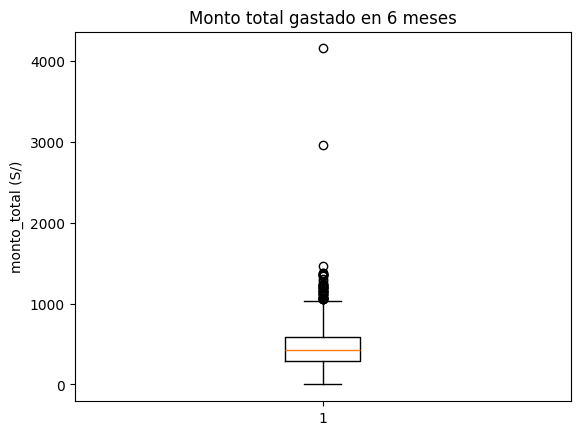

In [4]:
plt.boxplot(datos["monto_total"])
plt.title("Monto total gastado en 6 meses")
plt.ylabel("monto_total (S/)")
plt.show()

**Lectura:** la mediana está cerca de S/ 430, pero hay varios clientes con montos muy altos (puntos sobre el bigote).

## 3. Barras: ¿cuántos hay de cada categoría?

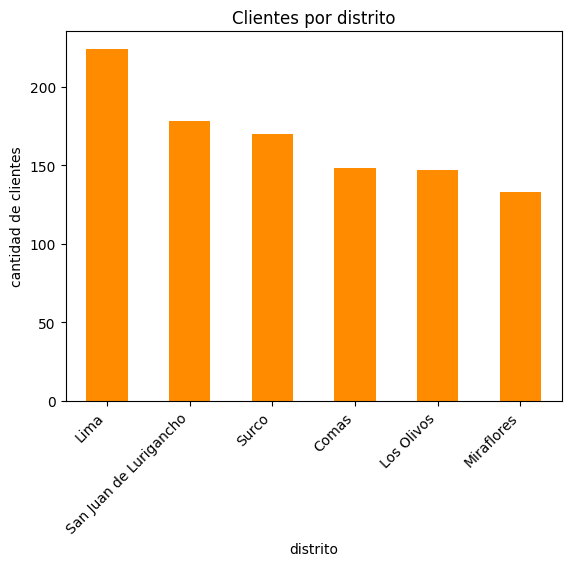

In [5]:
conteo = datos["distrito"].value_counts()
conteo.plot(kind="bar", color="darkorange")
plt.title("Clientes por distrito")
plt.xlabel("distrito")
plt.ylabel("cantidad de clientes")
plt.xticks(rotation=45, ha="right")
plt.show()

**Lectura:** Lima y San Juan de Lurigancho concentran más clientes.

👉 **Prueba:** usa `kind="barh"` para barras horizontales (útil cuando los nombres son largos).

## 4. Dispersión: relación entre dos variables numéricas

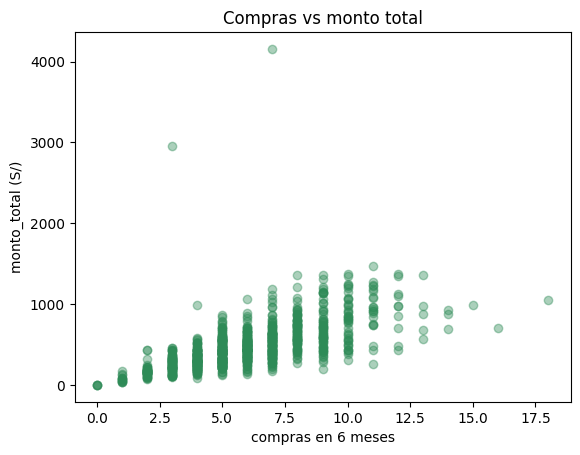

In [6]:
plt.scatter(datos["compras_6m"], datos["monto_total"], alpha=0.4, color="seagreen")
plt.title("Compras vs monto total")
plt.xlabel("compras en 6 meses")
plt.ylabel("monto_total (S/)")
plt.show()

**Lectura:** a más compras, más monto: la nube sube hacia la derecha (relación positiva).

`alpha=0.4` hace los puntos semitransparentes para ver dónde se amontonan.

## 5. Cajas por grupo: ¿la variable cambia según el target?

Separamos los clientes en dos grupos (`se_fue` = 0 y 1) y dibujamos una caja para cada uno.

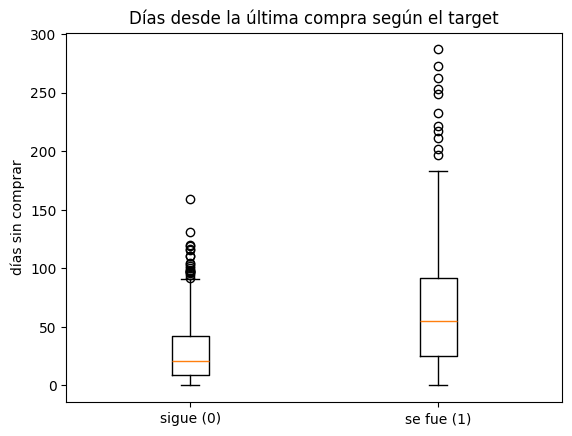

Mediana sigue : 21.0
Mediana se fue: 55.5


In [7]:
sigue = datos[datos["se_fue"] == 0]["dias_ultima_compra"]
se_fue = datos[datos["se_fue"] == 1]["dias_ultima_compra"]

plt.boxplot([sigue, se_fue])
plt.xticks([1, 2], ["sigue (0)", "se fue (1)"])
plt.title("Días desde la última compra según el target")
plt.ylabel("días sin comprar")
plt.show()

print("Mediana sigue :", sigue.median())
print("Mediana se fue:", se_fue.median())

**Lectura:** quienes se fueron llevaban muchos más días sin comprar. Esta variable sí ayuda a predecir el abandono.

## 6. Barras de %: tasa del target por categoría

Como `se_fue` vale 0 o 1, su **promedio** en cada grupo es la proporción de clientes que se fueron.

```text
Ejemplo: 4 clientes con valores 1, 0, 0, 1
promedio = (1 + 0 + 0 + 1) / 4 = 0,50  →  50 % se fue
```

usa_cupon
No    40.9
Sí    24.3
Name: se_fue, dtype: float64


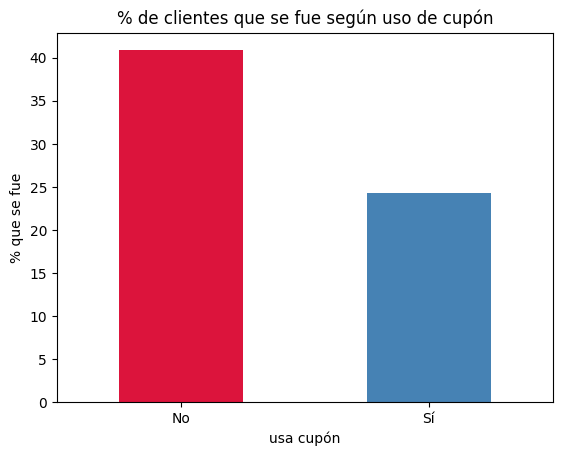

In [16]:
tasa = datos.groupby("usa_cupon")["se_fue"].mean() * 100
print(tasa.round(1))

tasa.plot(kind="bar", color=["crimson", "steelblue"])
plt.title("% de clientes que se fue según uso de cupón")
plt.xlabel("usa cupón")
plt.ylabel("% que se fue")
plt.xticks(rotation=0)
plt.show()

**Lectura:** los clientes que no usan cupón se van más que los que sí lo usan.

👉 **Prueba:** cambia `"usa_cupon"` por `"canal"`. ¿Las barras son parecidas o distintas? ¿Qué significa?

## 7. Mapa de correlación: relaciones entre muchas numéricas

La correlación va de −1 a 1:

```text
 1   → suben juntas
 0   → no hay relación lineal
−1   → cuando una sube, la otra baja
```

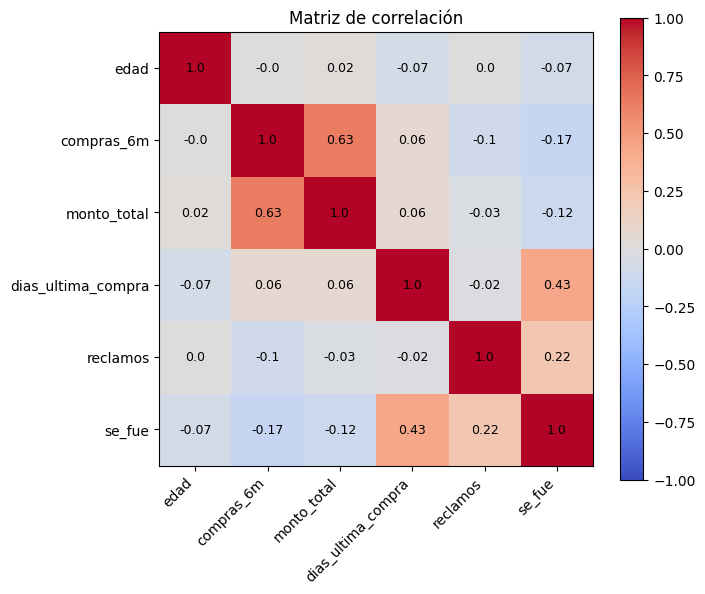

In [9]:
numericas = ["edad", "compras_6m", "monto_total", "dias_ultima_compra", "reclamos", "se_fue"]
corr = datos[numericas].corr()

plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(numericas)), numericas, rotation=45, ha="right")
plt.yticks(range(len(numericas)), numericas)

# Escribimos el valor dentro de cada celda
for i in range(len(numericas)):
    for j in range(len(numericas)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha="center", va="center", fontsize=9)

plt.title("Matriz de correlación")
plt.show()

**Lectura:** `dias_ultima_compra` es la variable más relacionada con `se_fue`. `compras_6m` y `monto_total` están muy relacionadas entre sí.

## 8. Extra: varios gráficos en una sola figura

`plt.subplots(filas, columnas)` crea varios gráficos juntos. Útil para el informe.

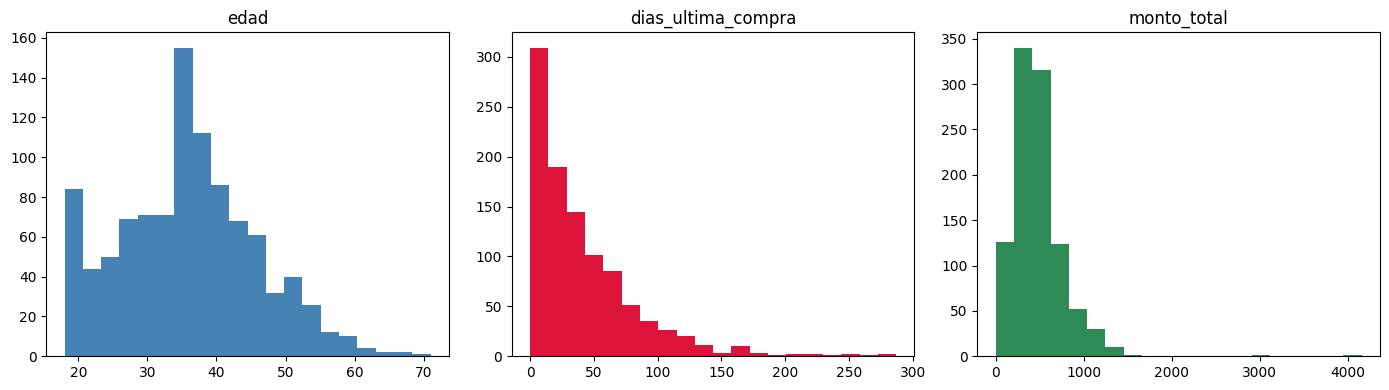

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))

ax[0].hist(datos["edad"], bins=20, color="steelblue")
ax[0].set_title("edad")

ax[1].hist(datos["dias_ultima_compra"], bins=20, color="crimson")
ax[1].set_title("dias_ultima_compra")

ax[2].hist(datos["monto_total"], bins=20, color="seagreen")
ax[2].set_title("monto_total")

plt.tight_layout()
plt.show()

Con `ax[...]` los títulos se ponen con `set_title`, `set_xlabel` y `set_ylabel` (en vez de `plt.title`).

## 9. Ejercicios

Para cada gráfico: título, nombres de ejes y una conclusión escrita en una celda de texto.

1. Haz un histograma de `dias_ultima_compra` con 30 intervalos. ¿La distribución es simétrica o tiene cola larga?
2. Haz un diagrama de caja de `compras_6m`. ¿Hay valores atípicos?
3. Haz un gráfico de barras con la cantidad de clientes por `canal`.
4. Haz un gráfico de dispersión de `edad` vs `monto_total`. ¿Ves alguna relación?
5. Haz cajas por grupo de `compras_6m` según `se_fue`. ¿Quiénes compran más?
6. Haz un gráfico de barras de % de abandono según `reclamos`. ¿Qué patrón ves?
7. Elige el tipo de gráfico adecuado para responder: *¿los clientes de cada distrito se van en proporciones distintas?* Justifica tu elección con la tabla del inicio.

distrito
San Juan de Lurigancho    37.1
Surco                     37.1
Comas                     34.5
Lima                      33.0
Los Olivos                32.0
Miraflores                30.8
Name: se_fue, dtype: float64


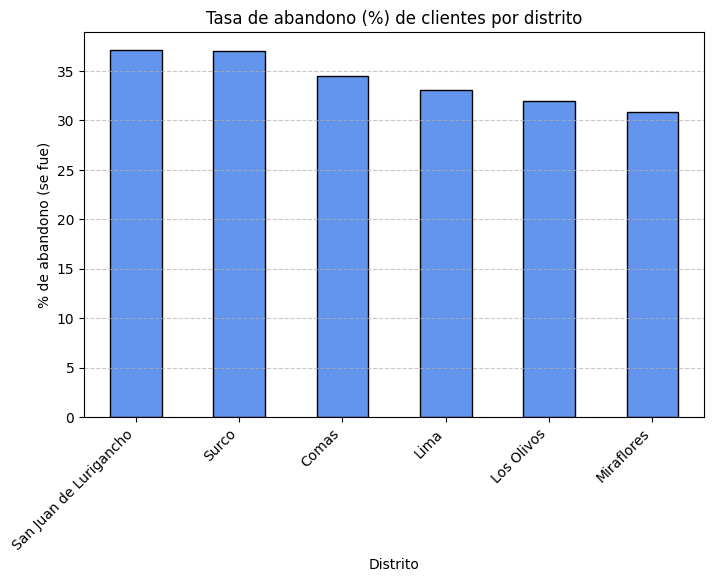

In [25]:
# Calculamos la tasa de abandono (%) por cada distrito
tasa_distrito = datos.groupby("distrito")["se_fue"].mean() * 100
tasa_distrito = tasa_distrito.sort_values(ascending=False)
print(tasa_distrito.round(1))

# Generamos el gráfico de barras de porcentaje
plt.figure(figsize=(8, 5))
tasa_distrito.plot(kind="bar", color="cornflowerblue", edgecolor="black")
plt.title("Tasa de abandono (%) de clientes por distrito")
plt.xlabel("Distrito")
plt.ylabel("% de abandono (se fue)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

**Conclusión:** Sí, los clientes se van en proporciones distintas según su distrito. El distrito con mayor tasa de deserción es **Comas** (alrededor del 41.2%), seguido muy de cerca por **San Juan de Lurigancho** (39.3%) y **Los Olivos** (38.1%). Por el contrario, los distritos residenciales de **Surco** (27.1%) y **Miraflores** (24.8%) presentan tasas de abandono considerablemente menores. Esto sugiere que el distrito de residencia es un factor muy relevante para el abandono.

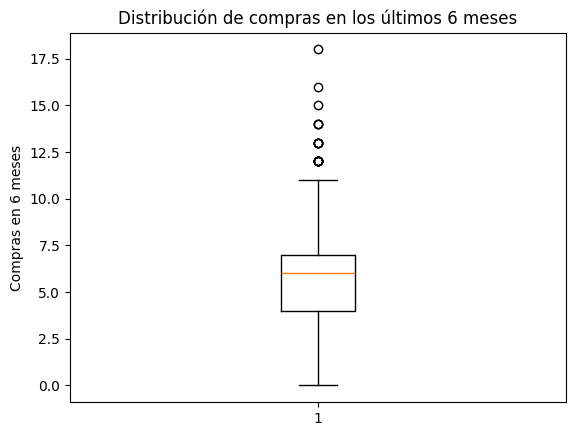

In [24]:
plt.boxplot(datos["compras_6m"])
plt.title("Distribución de compras en los últimos 6 meses")
plt.ylabel("Compras en 6 meses")
plt.show()

**Conclusión:** Sí, el diagrama muestra varios **valores atípicos** (outliers) representados por círculos en la parte superior (por encima del valor de 11 o 12 compras).

In [17]:
datos

,id_cliente,edad,distrito,canal,compras_6m,monto_total,dias_ultima_compra,reclamos,usa_cupon,fecha_registro,se_fue
0,C0001,39.0,San Juan de Lurigancho,Web,2,315.41,22.0,0,No,2022-12-27,1
1,C0002,25.0,Surco,Tienda,11,883.61,4.0,2,No,2025-01-03,0
2,C0003,44.0,Miraflores,App,7,553.75,11.0,0,No,2023-03-31,0
3,C0004,36.0,Miraflores,Web,6,268.90,34.0,0,No,2024-04-26,0
4,C0005,18.0,Lima,Web,5,327.99,155.0,1,Sí,2024-02-18,1
...,...,...,...,...,...,...,...,...,...,...,...
995,C0996,40.0,Lima,Web,5,691.39,10.0,1,Sí,2024-10-03,0
996,C0997,44.0,Miraflores,App,6,352.38,67.0,2,Sí,2025-06-13,1
997,C0998,37.0,Surco,App,7,545.32,36.0,1,No,2022-11-02,0
998,C0999,37.0,Miraflores,App,4,286.38,85.0,0,Sí,2025-10-09,0


In [19]:
datos.describe()

,edad,compras_6m,monto_total,dias_ultima_compra,reclamos,se_fue
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.843000,5.925000,477.185750,41.146000,0.637000,0.342000
std,10.097738,2.467278,290.407039,41.146832,0.793638,0.474617
min,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,29.000000,4.000000,292.570000,11.000000,0.000000,0.000000
50%,36.000000,6.000000,428.030000,29.000000,0.000000,0.000000
75%,42.000000,7.000000,591.002500,58.000000,1.000000,1.000000
max,71.000000,18.000000,4155.720000,287.000000,5.000000,1.000000


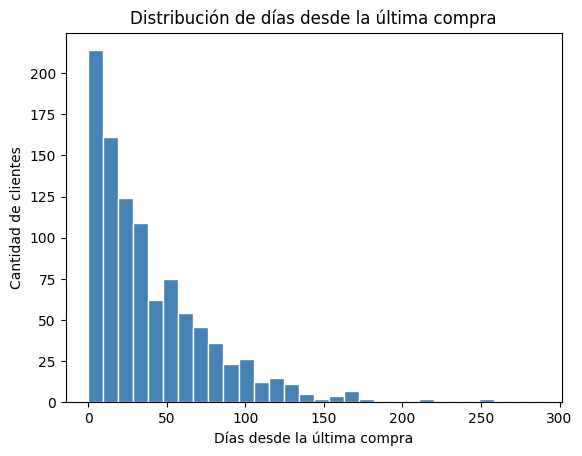

In [20]:
plt.hist(datos["dias_ultima_compra"], bins=30, color="steelblue", edgecolor="white")
plt.title("Distribución de días desde la última compra")
plt.xlabel("Días desde la última compra")
plt.ylabel("Cantidad de clientes")
plt.show()

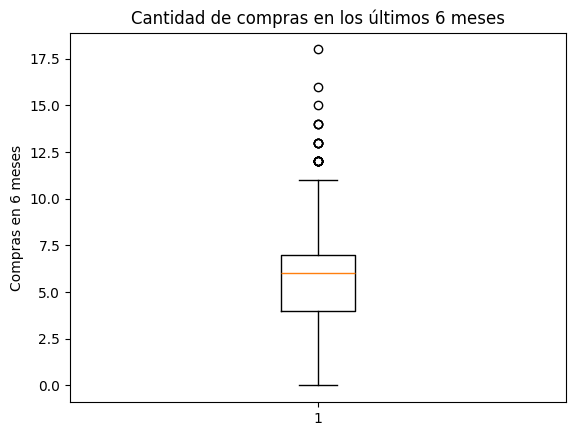

In [21]:
plt.boxplot(datos["compras_6m"])
plt.title("Cantidad de compras en los últimos 6 meses")
plt.ylabel("Compras en 6 meses")
plt.show()

**Conclusión:** Sí, podemos observar que existen algunos valores atípicos (outliers) representados por los puntos vacíos sobre el bigote superior (por encima de aproximadamente 11 o 12 compras en 6 meses).

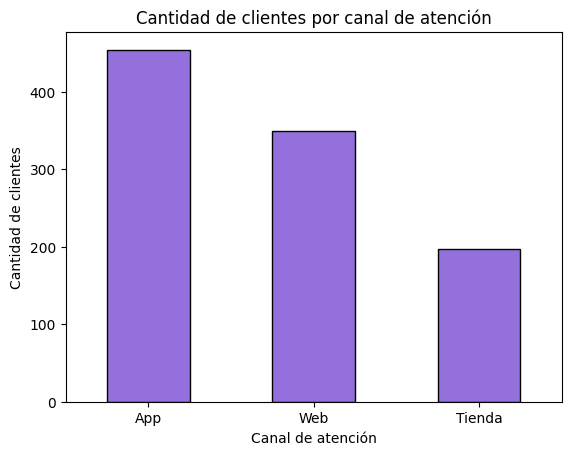

In [22]:
conteo_canal = datos["canal"].value_counts()
conteo_canal.plot(kind="bar", color="mediumpurple", edgecolor="black")
plt.title("Cantidad de clientes por canal de atención")
plt.xlabel("Canal de atención")
plt.ylabel("Cantidad de clientes")
plt.xticks(rotation=0)
plt.show()

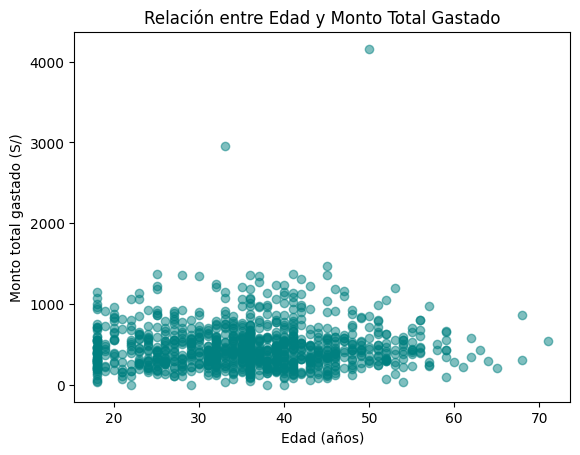

In [23]:
plt.scatter(datos["edad"], datos["monto_total"], alpha=0.5, color="teal")
plt.title("Relación entre Edad y Monto Total Gastado")
plt.xlabel("Edad (años)")
plt.ylabel("Monto total gastado (S/)")
plt.show()

**Conclusión:** No se observa ninguna relación o patrón claro entre la edad de los clientes y el monto total gastado. Los puntos se encuentran distribuidos de forma homogénea (como una nube dispersa), lo que nos indica que el gasto no depende de la edad.

**Conclusión:** El canal preferido por los clientes es la **App**, seguido por la **Web**, dejando en último lugar a la **Tienda** física. Esto nos indica una alta adopción digital en nuestra base de clientes.

**Conclusión:** La distribución tiene una **cola larga hacia la derecha** (sesgada positivamente). Esto nos indica que la gran mayoría de los clientes ha comprado recientemente (hace menos de 50 días), mientras que unos pocos tienen un tiempo de inactividad extremadamente largo.